In [1]:
import pandas as pd

mmv = pd.read_csv("../data/mmv_ChEMBL-IC50s-Sep2026.csv", sep="\t")
dndi = pd.read_csv("../data/dndi_compounds-IC50.csv", sep="\t")

dndi.head()

,chembl_id,pref_name,smiles,molecular_weight,logp,hba,hbd,psa,rtb,ro5_violations,aromatic_rings,heavy_atoms,pf_ec50_uM,tb_ic50_uM,tc_ic50_uM,tbrucei_ic50_uM,ld_ic50_uM,cp_ec50_uM,tg_ec50_uM,hepg2_cc50_uM,si_pf,si_tb,si_tc,si_tbrucei,si_ld,si_cp,si_tg
0,CHEMBL516073,NaN,O=[N+]([O-])c1cc2n(n1)CC(OCc1ccc(OC(F)(F)F)cc1...,359.26,2.67,7.0,0.0,88.65,5.0,0.0,2.0,25.0,NaN,NaN,8.2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CHEMBL3104530,NaN,O=C(c1ccccc1)N1CCC(N(c2ccc(C(F)(F)F)cc2)c2cccn...,425.45,5.54,3.0,0.0,36.44,4.0,1.0,3.0,31.0,NaN,NaN,0.0077,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CHEMBL4084773,NaN,O=[N+]([O-])c1cn2c(n1)OCC(OCc1ccc(OC(F)(F)F)cc...,373.29,3.06,7.0,0.0,88.65,5.0,0.0,2.0,26.0,NaN,NaN,4.2000,NaN,0.63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,CHEMBL3104477,NaN,CS(=O)(=O)c1ccc(N2CCC(N(c3ccc(Cl)cc3)c3cccnc3)...,441.98,4.95,5.0,0.0,53.51,5.0,0.0,3.0,30.0,NaN,NaN,0.0021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CHEMBL3104536,NaN,FC(F)(F)c1ccc(N2CCC(N(c3ccc(C(F)(F)F)cc3)c3ccc...,465.44,6.93,3.0,0.0,19.37,4.0,1.0,3.0,33.0,NaN,NaN,0.0179,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


DNDi has the same column names as MMV, but different records and fewer rows. The preview shows only the first five records.

In [2]:
print(dndi.columns.tolist())

if dndi.columns.tolist() == mmv.columns.tolist():
    print("The same column names in the same order")
else:
    print("The columns differ")

['chembl_id', 'pref_name', 'smiles', 'molecular_weight', 'logp', 'hba', 'hbd', 'psa', 'rtb', 'ro5_violations', 'aromatic_rings', 'heavy_atoms', 'pf_ec50_uM', 'tb_ic50_uM', 'tc_ic50_uM', 'tbrucei_ic50_uM', 'ld_ic50_uM', 'cp_ec50_uM', 'tg_ec50_uM', 'hepg2_cc50_uM', 'si_pf', 'si_tb', 'si_tc', 'si_tbrucei', 'si_ld', 'si_cp', 'si_tg']
The same column names in the same order


In [3]:
dndi.shape

(190, 27)

## Initial Data Exploration
The DNDi dataset contains 190 compound records and 27 variables. It has the same column names in the same order as the MMV/ChEMBL dataset, but fewer records. Initial exploration will examine its structure, data types and completeness before making preprocessing decisions.

### Data types and missing values

Check which columns contain numbers or text. The non-null count tells us how many values are available.

In [4]:
dndi.info()

<class 'pandas.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 27 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   chembl_id         190 non-null    str    
 1   pref_name         5 non-null      str    
 2   smiles            189 non-null    str    
 3   molecular_weight  190 non-null    float64
 4   logp              182 non-null    float64
 5   hba               182 non-null    float64
 6   hbd               182 non-null    float64
 7   psa               182 non-null    float64
 8   rtb               182 non-null    float64
 9   ro5_violations    182 non-null    float64
 10  aromatic_rings    182 non-null    float64
 11  heavy_atoms       182 non-null    float64
 12  pf_ec50_uM        0 non-null      float64
 13  tb_ic50_uM        4 non-null      float64
 14  tc_ic50_uM        172 non-null    float64
 15  tbrucei_ic50_uM   34 non-null     float64
 16  ld_ic50_uM        53 non-null     float64
 17  cp_ec50_

Compound IDs, names and SMILES are text. The other columns contain numbers. Count columns can be stored as floats when values are missing; 5.0 rotatable bonds is not automatically an error.

In [5]:
dndi.isnull().sum()

chembl_id             0
pref_name           185
smiles                1
molecular_weight      0
logp                  8
hba                   8
hbd                   8
psa                   8
rtb                   8
ro5_violations        8
aromatic_rings        8
heavy_atoms           8
pf_ec50_uM          190
tb_ic50_uM          186
tc_ic50_uM           18
tbrucei_ic50_uM     156
ld_ic50_uM          137
cp_ec50_uM          189
tg_ec50_uM          190
hepg2_cc50_uM       188
si_pf               190
si_tb               188
si_tc               188
si_tbrucei          188
si_ld               188
si_cp               190
si_tg               190
dtype: int64

Only 5 compounds have a preferred name, so we should not remove a compound just because its name is missing. One SMILES value is missing. Molecular weight is complete; each of the other eight descriptors has 8 missing values. A blank activity value means no value is available in this table. It does not tell us why it is missing, and we will not replace it with zero.

## Descriptive Statistics

Check the typical values, spread and range of the numeric columns. Read the minimum and maximum as well as the average. Empty columns have no numerical summary.

In [6]:
dndi.describe().T

,count,mean,std,min,25%,50%,75%,max
molecular_weight,190.0,418.804368,68.119472,322.0900,374.330000,418.36000,452.125000,924.0900
logp,182.0,3.987747,1.712624,-8.8600,2.970000,3.85000,5.230000,7.0100
hba,182.0,6.010989,2.264277,3.0000,4.000000,7.00000,7.000000,19.0000
hbd,182.0,0.269231,1.353954,0.0000,0.000000,0.00000,0.000000,13.0000
psa,182.0,75.676923,41.208487,19.3700,43.160000,88.65000,101.540000,347.3200
rtb,182.0,4.934066,1.575378,3.0000,4.000000,5.00000,6.000000,20.0000
ro5_violations,182.0,0.335165,0.558980,0.0000,0.000000,0.00000,1.000000,3.0000
aromatic_rings,182.0,2.637363,0.576069,0.0000,2.000000,3.00000,3.000000,3.0000
heavy_atoms,182.0,29.675824,4.096808,23.0000,27.000000,30.00000,32.000000,65.0000
pf_ec50_uM,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Duplicate checks

First check identical rows, then repeated compound IDs. These checks cover DNDi only. Overlap with MMV will be checked separately.

In [7]:
# Count exact copies of whole rows.
dndi.duplicated().sum()

np.int64(0)

In [8]:
# Count repeated compound IDs.
dndi["chembl_id"].duplicated().sum()

np.int64(0)

Both checks return 0. There are no duplicate rows or repeated compound IDs within DNDi, so no records need to be removed for these reasons.

### Activity coverage

Count compounds with a value for each outcome. These are available values in our table, not the number of original experiments.

In [9]:
activity_columns = [
    "pf_ec50_uM", "tb_ic50_uM", "tc_ic50_uM",
    "tbrucei_ic50_uM", "ld_ic50_uM", "cp_ec50_uM", "tg_ec50_uM"
]

dndi[activity_columns].count().sort_values(ascending=False)

tc_ic50_uM         172
ld_ic50_uM          53
tbrucei_ic50_uM     34
tb_ic50_uM           4
cp_ec50_uM           1
pf_ec50_uM           0
tg_ec50_uM           0
dtype: int64

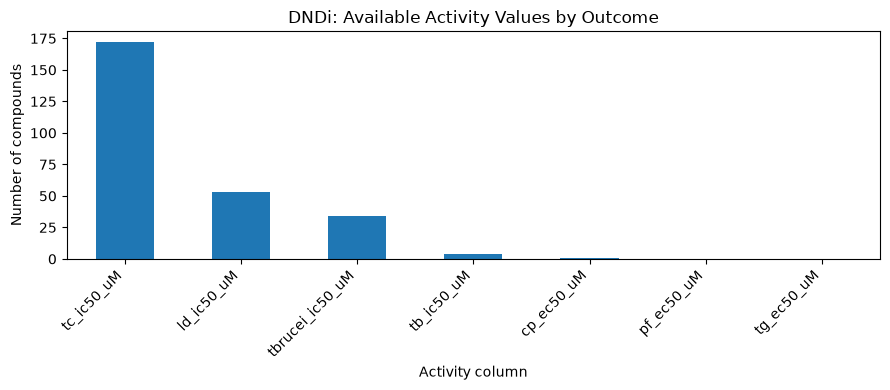

In [10]:
import matplotlib.pyplot as plt

activity_counts = dndi[activity_columns].count().sort_values(ascending=False)
activity_counts.plot(kind="bar", figsize=(9, 4))
plt.title("DNDi: Available Activity Values by Outcome")
plt.xlabel("Activity column")
plt.ylabel("Number of compounds")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The best-covered outcome is `tc_ic50_uM`: 172 of 190 compounds (90.5%). There are 53 values for `ld_ic50_uM` and 34 for `tbrucei_ic50_uM`, but only 4 for `tb_ic50_uM` and 1 for `cp_ec50_uM`. No values are available for `pf_ec50_uM` or `tg_ec50_uM`. We cannot make equally reliable comparisons for every outcome.

### Molecular descriptors

These numbers describe chemical properties. Inspect them separately from the activity outcomes.

In [11]:
descriptor_columns = [
    "molecular_weight", "logp", "hba", "hbd", "psa", "rtb",
    "ro5_violations", "aromatic_rings", "heavy_atoms"
]

dndi[descriptor_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
molecular_weight,190.0,418.804368,68.119472,322.09,374.33,418.36,452.125,924.09
logp,182.0,3.987747,1.712624,-8.86,2.97,3.85,5.230,7.01
hba,182.0,6.010989,2.264277,3.00,4.00,7.00,7.000,19.00
hbd,182.0,0.269231,1.353954,0.00,0.00,0.00,0.000,13.00
psa,182.0,75.676923,41.208487,19.37,43.16,88.65,101.540,347.32
rtb,182.0,4.934066,1.575378,3.00,4.00,5.00,6.000,20.00
ro5_violations,182.0,0.335165,0.558980,0.00,0.00,0.00,1.000,3.00
aromatic_rings,182.0,2.637363,0.576069,0.00,2.00,3.00,3.000,3.00
heavy_atoms,182.0,29.675824,4.096808,23.00,27.00,30.00,32.000,65.00


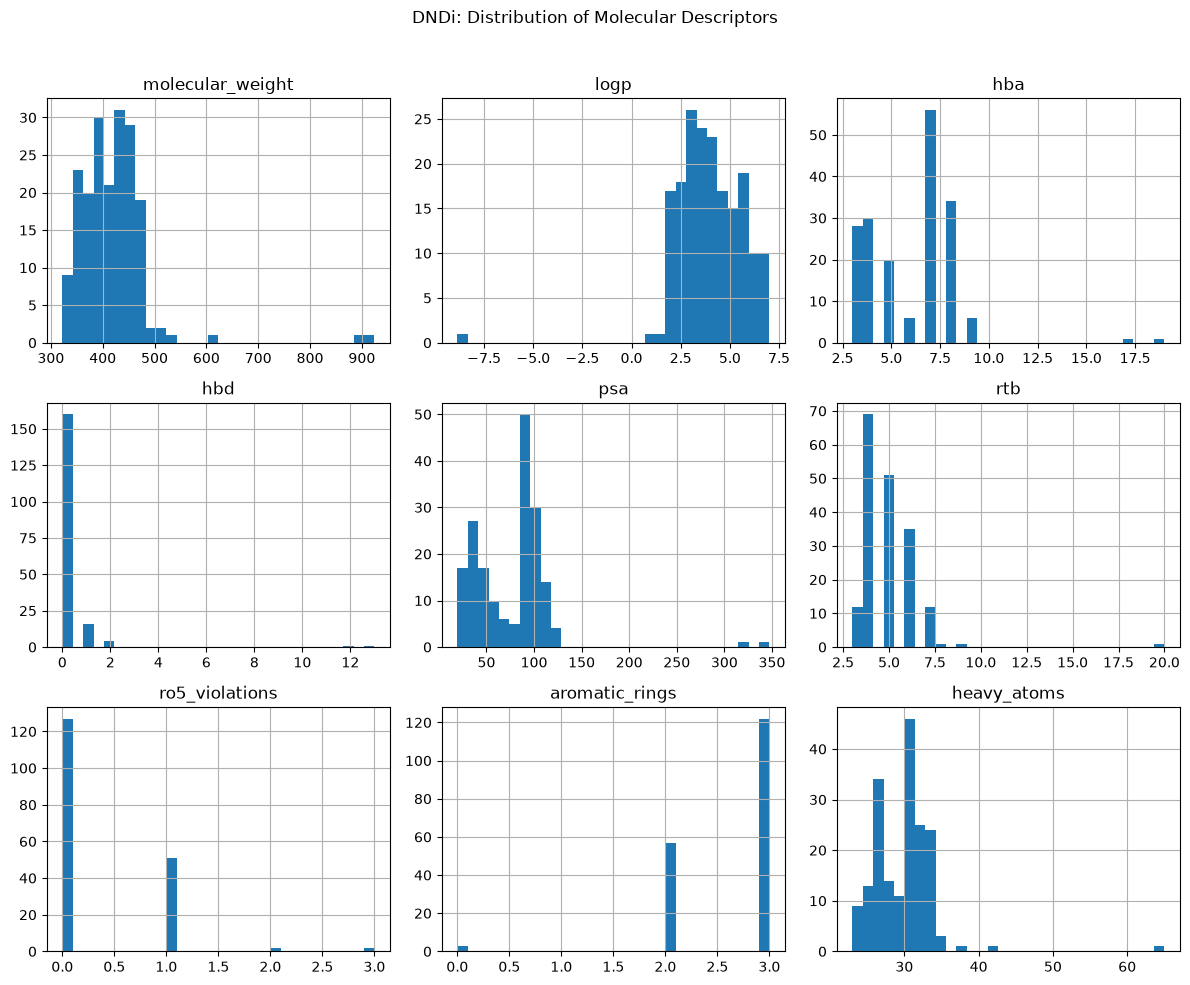

In [12]:
# First look at the shape of each property.
dndi[descriptor_columns].hist(figsize=(12, 10), bins=30)
plt.suptitle("DNDi: Distribution of Molecular Descriptors")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

The middle 50% of available rotatable-bond counts are between 4 and 6; the median is 5 and the maximum is 20. Aromatic-ring counts are concentrated at 2 and 3. Of 182 compounds with Rule-of-Five data, 127 have zero violations (69.8%). Count plots may be clearer for properties with only a few integer values. Unusual high values deserve checking, but should not be removed just because they are large.

## Biological Activity Exploration

Follow the MMV notebook: numerical summary, original-scale histogram, largest values and log-scale histogram. Use `tc_ic50_uM`, the best-covered DNDi outcome. Bashir used `pf_ec50_uM`, which is entirely missing here.

In [13]:
dndi["tc_ic50_uM"].describe()

count    172.000000
mean       2.386267
std        8.213190
min        0.000600
25%        0.015000
50%        0.150000
75%        0.692500
max       51.000000
Name: tc_ic50_uM, dtype: float64

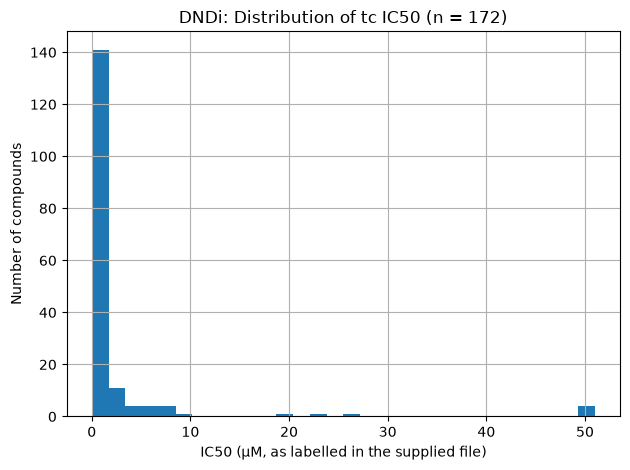

In [14]:
dndi["tc_ic50_uM"].hist(bins=30)
plt.title("DNDi: Distribution of tc IC50 (n = 172)")
plt.xlabel("IC50 (µM, as labelled in the supplied file)")
plt.ylabel("Number of compounds")
plt.tight_layout()
plt.show()

The median is 0.15 µM, the mean is about 2.39 µM and the maximum is 51 µM. A small number of large values pull the mean above the median. This is a right-skewed distribution.

In [15]:
# Inspect large values without deleting them.
dndi.nlargest(10, "tc_ic50_uM")[
    ["chembl_id", "pref_name", "tc_ic50_uM"]
]

,chembl_id,pref_name,tc_ic50_uM
41,CHEMBL4067141,NaN,51.0000
61,CHEMBL1836062,NaN,51.0000
117,CHEMBL4095345,NaN,51.0000
178,CHEMBL4070883,NaN,50.0000
39,CHEMBL125,MILTEFOSINE,26.0892
177,CHEMBL4071028,NaN,23.0000
63,CHEMBL1944704,NaN,19.0000
152,CHEMBL227875,PRETOMANID,10.0000
0,CHEMBL516073,NaN,8.2000
133,CHEMBL4091825,NaN,7.8000


Several records have values of 50 or 51 µM. Keep them for now. This table does not tell us whether they are exact measurements, assay limits or processed summaries. We need the source records or extraction documentation before deciding how to handle them.

Non-positive tc IC50 values: 0


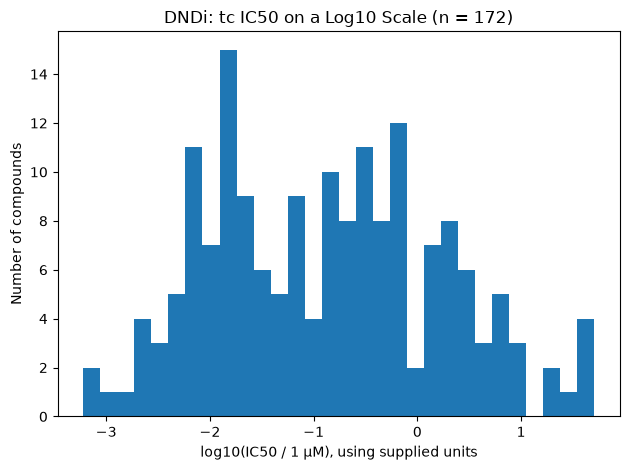

In [16]:
import numpy as np

# Exclude missing values only for this particular activity plot.
tc_data = dndi["tc_ic50_uM"].dropna()

# Log10 needs positive values. Check before transforming.
print("Non-positive tc IC50 values:", (tc_data <= 0).sum())
if (tc_data <= 0).any():
    raise ValueError("Investigate non-positive values before taking log10.")

log_tc_ic50 = np.log10(tc_data)
plt.hist(log_tc_ic50, bins=30)
plt.title(f"DNDi: tc IC50 on a Log10 Scale (n = {len(tc_data)})")
plt.xlabel("log10(IC50 / 1 µM), using supplied units")
plt.ylabel("Number of compounds")
plt.tight_layout()
plt.show()

The log plot spreads out small values and compresses large ones, making the distribution easier to see. This follows Bashir's log10 approach; it is not pIC50. The original concentrations have not been changed. Check endpoint definitions and units against the dataset documentation before creating pIC50 or pEC50 columns.

## Initial findings and next steps

- DNDi has 190 records and the same column structure as MMV.
- No duplicate rows or repeated IDs were found within DNDi.
- Most descriptors are available, but activity coverage varies greatly.
- `tc_ic50_uM` has the largest activity sample and a right-skewed distribution.

This stage inspects the data without filling gaps or removing unusual records. Next, compare both datasets, check shared compounds and descriptor validity, and document common preprocessing decisions. Keep missing activity as missing. For each property–activity analysis, select rows where that particular pair is available.